# TP5 - feature selection

Testing filter and wrapper methods on the breast cancer dataset.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time


## Dataset


In [2]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
X = cancer.data.copy()
y = cancer.target.copy()
print('Shape:', X.shape)
print('Target: 0 = malignant, 1 = benign')
print(X.head())


Shape: (569, 30)
Target: 0 = malignant, 1 = benign
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst rad

In [3]:
print('Missing:', int(X.isna().sum().sum()))
print('Duplicates:', int(X.duplicated().sum()))
print(y.value_counts())


Missing: 0
Duplicates: 0
target
1    357
0    212
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Train size:', X_train.shape, 'Test size:', X_test.shape)


Train size: (398, 30) Test size: (171, 30)


## Part A - baseline with all 30 features


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print('Dummy test accuracy:', round(dummy.score(X_test, y_test), 4))

start = time.perf_counter()
baseline = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000, random_state=42))])
baseline.fit(X_train, y_train)
print('Time:', round(time.perf_counter() - start, 4), 'seconds')
print('Train acc:', round(accuracy_score(y_train, baseline.predict(X_train)), 4))
print('Test acc:', round(accuracy_score(y_test, baseline.predict(X_test)), 4))


Dummy test accuracy: 0.6257
Time: 0.0512 seconds
Train acc: 0.9874
Test acc: 0.9883


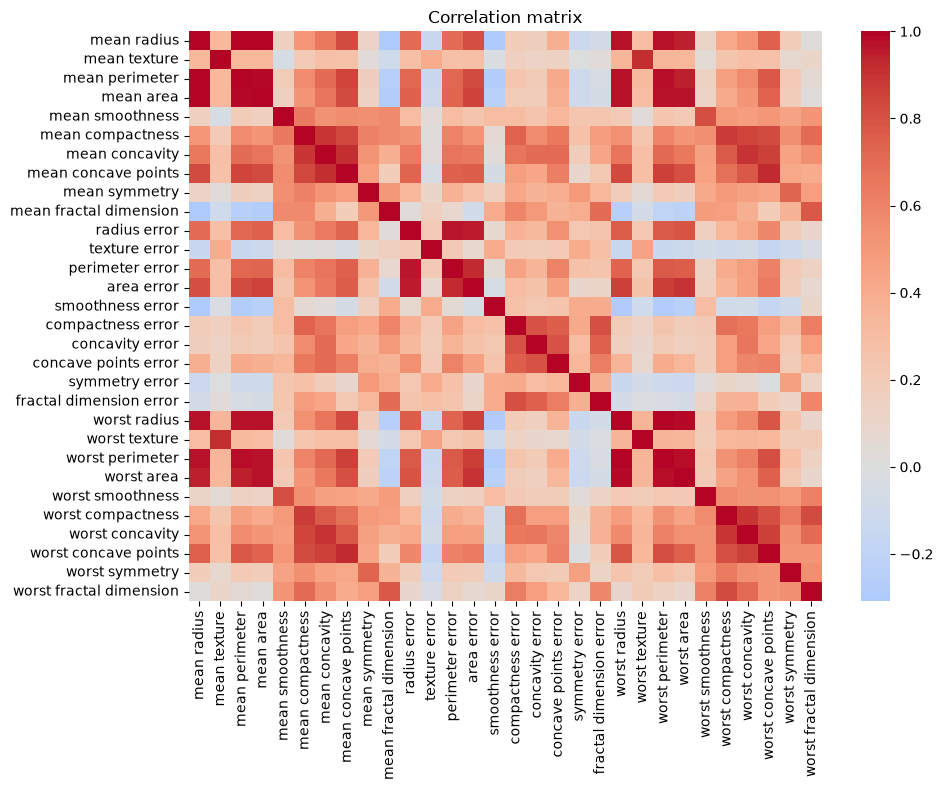

In [6]:
corr = X_train.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()


## Part B - filter methods


In [17]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif

for threshold in [0, 0.01, 0.1]:
    vt = VarianceThreshold(threshold=threshold)
    vt.fit(X_train)
    kept = int(vt.get_support().sum())
    print(f'Threshold {threshold}: {kept} features kept, {30-kept} removed')


Threshold 0: 30 features kept, 0 removed
Threshold 0.01: 14 features kept, 16 removed
Threshold 0.1: 11 features kept, 19 removed


In [8]:
def remove_correlated(X_data, y_data, threshold):
    corr = X_data.corr().abs()
    y_vals = np.asarray(y_data)
    target_corr = X_data.apply(lambda col: abs(np.corrcoef(col.to_numpy(), y_vals)[0, 1]))
    keep = list(X_data.columns)
    for i, col1 in enumerate(X_data.columns):
        if col1 not in keep:
            continue
        for col2 in X_data.columns[i+1:]:
            if col2 not in keep:
                continue
            if corr.loc[col1, col2] > threshold:
                if target_corr[col1] >= target_corr[col2]:
                    keep.remove(col2)
                else:
                    keep.remove(col1)
                    break
    return keep

for th in [0.95, 0.90, 0.80]:
    kept = remove_correlated(X_train, y_train, th)
    print(f'Threshold {th}: {len(kept)} features kept')


Threshold 0.95: 23 features kept
Threshold 0.9: 19 features kept
Threshold 0.8: 13 features kept


In [9]:
f_vals, p_vals = f_classif(X_train, y_train)
mi = mutual_info_classif(X_train, y_train, random_state=42)
score_table = pd.DataFrame({'Feature': X.columns, 'ANOVA F': f_vals, 'Mutual info': mi}).set_index('Feature')
print(score_table.sort_values('ANOVA F', ascending=False).head(10).round(3))


                      ANOVA F  Mutual info
Feature                                   
worst concave points  732.283        0.459
worst perimeter       643.460        0.480
mean concave points   635.026        0.441
worst radius          617.391        0.456
mean perimeter        519.551        0.409
worst area            486.344        0.454
mean radius           480.594        0.366
mean area             450.499        0.356
mean concavity        365.481        0.361
worst concavity       335.294        0.335


In [10]:
k_values = [2, 5, 10, 15, 20, 25, 30]
rows = []
for sname, sfunc in [('F-score', f_classif), ('MI', mutual_info_classif)]:
    for k in k_values:
        model = Pipeline([('sc', StandardScaler()), ('sel', SelectKBest(sfunc, k=k)), ('lr', LogisticRegression(max_iter=1000, random_state=42))])
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
        rows.append([sname, k, scores.mean(), scores.std()])

uni_df = pd.DataFrame(rows, columns=['Score', 'K', 'Mean acc', 'Std'])
print(uni_df.round(4))


      Score   K  Mean acc     Std
0   F-score   2    0.9347  0.0148
1   F-score   5    0.9523  0.0146
2   F-score  10    0.9523  0.0146
3   F-score  15    0.9598  0.0166
4   F-score  20    0.9874  0.0139
5   F-score  25    0.9824  0.0189
6   F-score  30    0.9824  0.0189
7        MI   2    0.9373  0.0284
8        MI   5    0.9548  0.0151
9        MI  10    0.9523  0.0146
10       MI  15    0.9598  0.0166
11       MI  20    0.9799  0.0128
12       MI  25    0.9824  0.0189
13       MI  30    0.9824  0.0189


## Part C - wrapper methods


In [11]:
from sklearn.feature_selection import SequentialFeatureSelector, RFE, RFECV

start = time.perf_counter()
sfs = SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction='forward', cv=cv)
sfs.fit(StandardScaler().fit_transform(X_train), y_train)
forward_feats = list(X.columns[sfs.get_support()])
print('Forward:', forward_feats)
print('Time:', round(time.perf_counter() - start, 2), 'sec')


Forward: ['mean radius', 'mean texture', 'mean perimeter', 'mean compactness', 'texture error', 'smoothness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness']
Time: 35.09 sec


In [12]:
start = time.perf_counter()
back_sfs = SequentialFeatureSelector(LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10, direction='backward', cv=cv)
back_sfs.fit(StandardScaler().fit_transform(X_train), y_train)
backward_feats = list(X.columns[back_sfs.get_support()])
print('Backward:', backward_feats)
print('Time:', round(time.perf_counter() - start, 2), 'sec')


Backward: ['texture error', 'area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst concavity', 'worst symmetry']
Time: 35.28 sec


In [13]:
rfe = RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10)
rfe.fit(StandardScaler().fit_transform(X_train), y_train)
rfe_feats = list(X.columns[rfe.support_])
print('RFE:', rfe_feats)

rfecv = RFECV(estimator=LogisticRegression(max_iter=1000, random_state=42), step=1, cv=cv, scoring='accuracy')
rfecv.fit(StandardScaler().fit_transform(X_train), y_train)
print('RFECV optimal n:', rfecv.n_features_)
print('RFECV feats:', list(X.columns[rfecv.support_]))


RFE: ['mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']
RFECV optimal n: 8
RFECV feats: ['mean area', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points']


## Part D - noise and leakage


In [14]:
rng = np.random.default_rng(42)
noise = rng.normal(size=(len(X), 20))
noise_cols = [f'noise_{i:02d}' for i in range(20)]
X_noise = pd.concat([X.reset_index(drop=True), pd.DataFrame(noise, columns=noise_cols)], axis=1)
Xn_train, Xn_test, yn_train, yn_test = train_test_split(X_noise, y, test_size=0.30, stratify=y, random_state=42)

print('Added', len(noise_cols), 'noise columns')


Added 20 noise columns


In [15]:
from sklearn.svm import SVC

incorrect_sel = SelectKBest(f_classif, k=10)
Xn_reduced = incorrect_sel.fit_transform(Xn_train, yn_train)
incorrect_scores = cross_val_score(Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000, random_state=42))]), Xn_reduced, yn_train, cv=cv, scoring='accuracy')

correct_model = Pipeline([('sc', StandardScaler()), ('sel', SelectKBest(f_classif, k=10)), ('lr', LogisticRegression(max_iter=1000, random_state=42))])
correct_scores = cross_val_score(correct_model, Xn_train, yn_train, cv=cv, scoring='accuracy')

print('Incorrect (selector outside CV):', round(incorrect_scores.mean(), 4))
print('Correct (selector inside pipeline):', round(correct_scores.mean(), 4))


Incorrect (selector outside CV): 0.9523
Correct (selector inside pipeline): 0.9523


## Final table


In [16]:
chosen_k = {'F-score': 10, 'MI': 10}

final_rows = []
methods = {
    'Baseline': Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000, random_state=42))]),
    'F-score': Pipeline([('sc', StandardScaler()), ('sel', SelectKBest(f_classif, k=10)), ('lr', LogisticRegression(max_iter=1000, random_state=42))]),
    'Forward': Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000, random_state=42))]),
}

feat_dict = {'Baseline': list(X.columns), 'F-score': list(X.columns), 'Forward': forward_feats}

for name, model in methods.items():
    feats = feat_dict[name]
    start = time.perf_counter()
    model.fit(X_train[feats], y_train)
    pred = model.predict(X_test[feats])
    final_rows.append([name, len(feats), round(accuracy_score(y_test, pred), 4), round(time.perf_counter() - start, 4)])

final_df = pd.DataFrame(final_rows, columns=['Method', 'Features', 'Test acc', 'Time (s)'])
print(final_df)


     Method  Features  Test acc  Time (s)
0  Baseline        30    0.9883    0.0421
1   F-score        30    0.9357    0.0219
2   Forward        10    0.9357    0.0197


## Conclusion

Filter methods are fast, wrapper methods take longer but might find better subsets.

The leakage test shows it's important to keep feature selection inside cross-validation, otherwise results look too good.
